In [1]:
# Import libraries for data processing, visualization, and saving models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Import Google Colab file upload and download functions
from google.colab import files

# Import tools for splitting data and preprocessing features
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import three machine learning classification algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

# Upload the cleaned repairs CSV file from your computer
files.upload()

# Read the uploaded dataset into a Pandas DataFrame
df = pd.read_csv("cleaned_repairs.csv", low_memory=False)

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display the count of each repair status, including missing values
print(df["repair_status"].value_counts(dropna=False))

Saving cleaned_repairs.csv to cleaned_repairs.csv
Dataset shape: (305649, 11)
repair_status
Fixed          165144
End of life     77709
Repairable      54049
Unknown          8747
Name: count, dtype: int64


In [ ]:
df = df.dropna(subset=["repair_status"]).copy()
df["repair_status"] = df["repair_status"].astype(str).str.strip()

df = df[
    df["repair_status"].ne("") &
    df["repair_status"].str.lower().ne("nan")
].copy()

dates = pd.to_datetime(df["event_date"], errors="coerce")
df["event_year"] = dates.dt.year.astype(float)
df["event_month"] = dates.dt.month.astype(float)

numeric_features = [
    c for c in ["product_age", "year_of_manufacture",
                "event_year", "event_month"] if c in df.columns
]

categorical_features = [
    c for c in ["product_category_id", "brand",
                "country", "data_provider"] if c in df.columns
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df["repair_status"].copy()

for c in numeric_features:
    X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)

for c in categorical_features:
    X[c] = X[c].astype("string").fillna("Unknown").astype(str)

valid = y.map(y.value_counts()) >= 2
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 244519
Testing records: 61130


In [ ]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant",
                                  fill_value="Unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=20,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    )
}

models = {}

for name, clf in classifiers.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    model.fit(X_train, y_train)
    models[name] = model

print("All models trained successfully.")

All models trained successfully.



 Decision Tree
              precision    recall  f1-score   support

 End of life       0.33      0.52      0.41     15542
       Fixed       0.68      0.19      0.30     33029
  Repairable       0.27      0.50      0.35     10810
     Unknown       0.16      0.71      0.26      1749

    accuracy                           0.34     61130
   macro avg       0.36      0.48      0.33     61130
weighted avg       0.50      0.34      0.33     61130


 Random Forest
              precision    recall  f1-score   support

 End of life       0.34      0.42      0.38     15542
       Fixed       0.65      0.22      0.33     33029
  Repairable       0.26      0.53      0.35     10810
     Unknown       0.15      0.72      0.25      1749

    accuracy                           0.34     61130
   macro avg       0.35      0.47      0.33     61130
weighted avg       0.49      0.34      0.35     61130


 Logistic Regression
              precision    recall  f1-score   support

 End of life       0.

,Model,Accuracy,Precision,Recall,F1 Score
2,Logistic Regression,0.3727,0.4925,0.3727,0.3858
1,Random Forest,0.3434,0.4898,0.3434,0.3453
0,Decision Tree,0.3431,0.5024,0.3431,0.3333


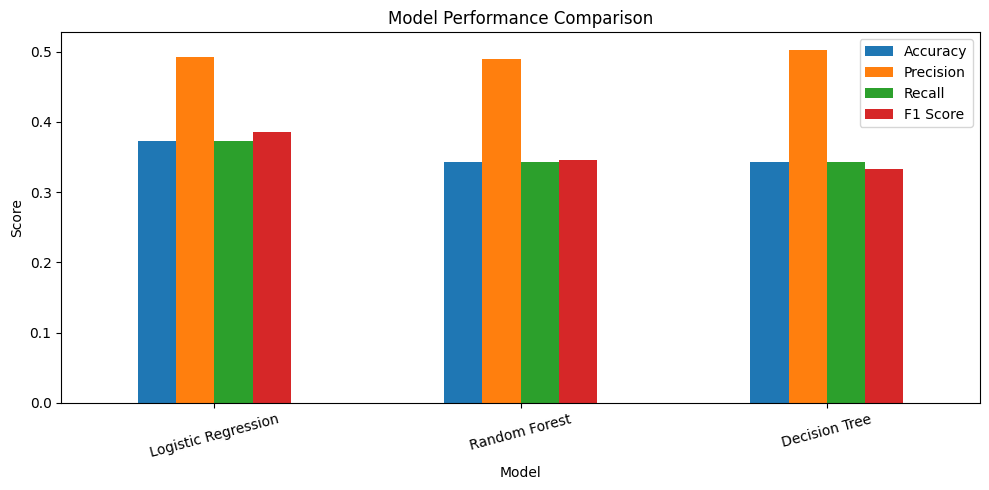

In [ ]:
results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    })

    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
)

display(results_df.round(4))

results_df.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

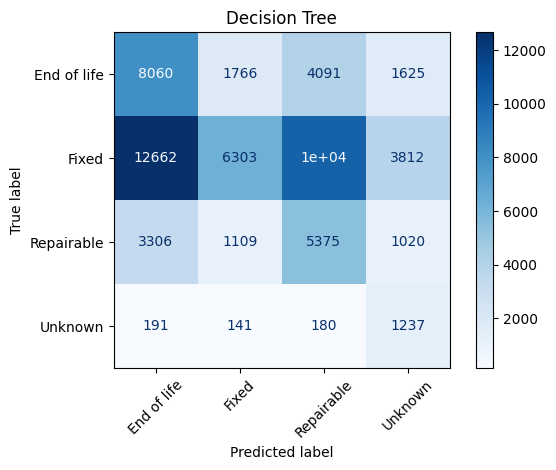

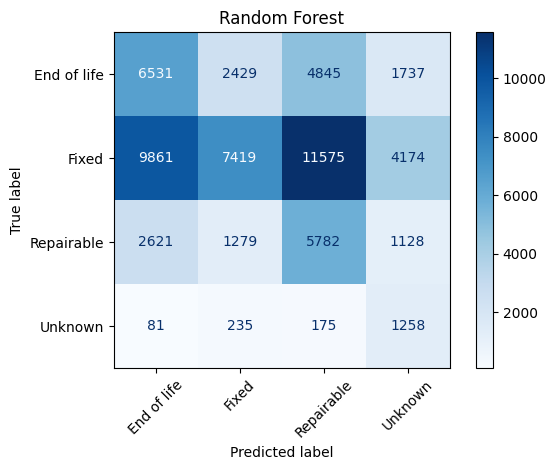

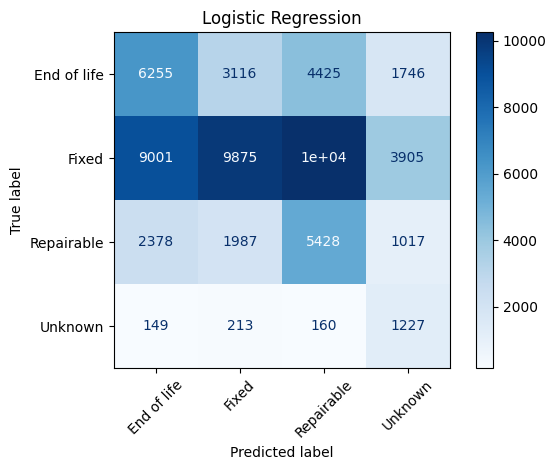

In [ ]:
for name, model in models.items():
    pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, xticks_rotation=45, cmap="Blues"
    )
    plt.title(name)
    plt.tight_layout()
    plt.show()

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

joblib.dump(best_model, "best_repair_model.joblib")
results_df.to_csv("model_comparison.csv", index=False)

print("Best model:", best_name)
print("Saved best_repair_model.joblib and model_comparison.csv")

Best model: Logistic Regression
Saved best_repair_model.joblib and model_comparison.csv


In [ ]:
def repair_recommendation(status):
    status = str(status).lower()

    if "fixed" in status:
        return "Verify the repair and return the product to the customer."
    elif "repairable" in status:
        return "Arrange diagnosis and estimate repair cost and parts."
    elif "end of life" in status or "end-of-life" in status:
        return "Review safety, repair cost, parts availability and alternatives."
    elif "unknown" in status:
        return "Collect more information before deciding."
    else:
        return "Review the case manually before making a decision."


def predict_repair(input_data):
    if isinstance(input_data, dict):
        input_data = pd.DataFrame([input_data])
    else:
        input_data = input_data.copy()

    if "event_date" in input_data.columns:
        dates = pd.to_datetime(input_data["event_date"], errors="coerce")
        input_data["event_year"] = dates.dt.year.astype(float)
        input_data["event_month"] = dates.dt.month.astype(float)

    for c in features:
        if c not in input_data.columns:
            input_data[c] = np.nan

    input_data = input_data[features].copy()

    for c in numeric_features:
        input_data[c] = pd.to_numeric(input_data[c], errors="coerce")

    for c in categorical_features:
        input_data[c] = input_data[c].astype("string").fillna("Unknown").astype(str)

    status = best_model.predict(input_data)[0]
    probabilities = best_model.predict_proba(input_data)[0]

    return {
        "Predicted status": status,
        "Probabilities": pd.Series(
            probabilities, index=best_model.classes_
        ).sort_values(ascending=False),
        "Recommendation": repair_recommendation(status)
    }


result = predict_repair(X_test.iloc[0].to_dict())

print("Predicted status:", result["Predicted status"])
print("\nEstimated probabilities:")
display(result["Probabilities"].round(3))
print("\nRecommendation:", result["Recommendation"])

Predicted status: Fixed

Estimated probabilities:


,0
Fixed,0.502
End of life,0.266
Repairable,0.232
Unknown,0.000



Recommendation: Verify the repair and return the product to the customer.


In [ ]:
files.download("best_repair_model.joblib")
files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>